In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader, Subset, random_split
import copy
import numpy as np
import os
import sys
import pandas as pd
from tqdm import tqdm


In [2]:

### CONFIG ###
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# sim settings
FED_ROUNDS = 20           
TOTAL_CLIENTS = 5
CLIENTS_PER_ROUND = 5     
LOCAL_EPOCHS = 3
LOCAL_EPOCHS_FEDDF = 5
SERVER_FUSION_EPOCHS = 3
BATCH_SIZE = 512 
CLIENT_LR = 0.005
SERVER_LR = 0.0001
NUM_WORKERS = 8

# distillation 
TEMP = 2.0
ALPHA = 0.5
BETA = 0.5

# adaptive pruning 
CLIENT_PRUNING_RATES = [0.2, 0.3, 0.4, 0.5, 0.5]


PATH_BASELINE = 'resnet18_best.pth'
PATH_STUDENT = 'big_student_distilled_best.pth'





In [3]:

######### MODEL DEFINITIONS ########
# models defined in part 1


def get_teacher_model():
    model = resnet18(num_classes=10)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model

class BiggerStudent(nn.Module):
    def __init__(self):
        super(BiggerStudent, self).__init__()
        # 3 -> 32
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # 32 -> 64
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # 64 -> 128
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x)
        x = x.flatten(1)
        x = self.fc(x)
        return x


############### HELPERS ###################


def get_model_size_mb(model): #gets real model size 
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    for buffer in model.buffers():
        param_size += buffer.nelement() * buffer.element_size()
    return param_size / 1e6

def get_compressed_size_mb(model): #simulates compressed model size
    total_nonzero = 0
    for name, param in model.named_parameters():
        if 'weight' in name:
            tensor = param.data.cpu()
            nonzero = torch.count_nonzero(tensor).item()
            total_nonzero += nonzero
        else:
            total_nonzero += param.nelement()
            
    return (total_nonzero * 1) / 1e6 


def apply_adaptive_pruning(model, amount):
    if amount <= 0: return model
    parameters_to_prune = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            parameters_to_prune.append((module, 'weight'))

    prune.global_unstructured(
        parameters_to_prune,
        pruning_method=prune.L1Unstructured,
        amount=amount,
    )
    for module, _ in parameters_to_prune:
        prune.remove(module, 'weight')
    return model

def distillation_loss(student_logits, teacher_logits, T=2.0):
    soft_targets = F.softmax(teacher_logits / T, dim=-1)
    soft_prob = F.log_softmax(student_logits / T, dim=-1)
    return nn.KLDivLoss(reduction='batchmean')(soft_prob, soft_targets) * (T**2)

def evaluate(model, loader, device):
    model.eval()
    correct = 0; total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

def federated_averaging(models):
    w_avg = copy.deepcopy(models[0].state_dict())
    for k in w_avg.keys():
        for i in range(1, len(models)):
            w_avg[k] += models[i].state_dict()[k]
        w_avg[k] = torch.div(w_avg[k], len(models))
    return w_avg

In [4]:
#### SIM LOGIC

def run_standard_fedavg(client_loaders, test_loader):
    print(f"\n[1/2] Starting Standard FL (FedAvg) with ResNet18...")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    else:
        print("weights not loading")
    
    history = []
    total_uplink_mb = 0
    model_size = get_model_size_mb(global_model)
    best_acc = 0.0
    
    for round_idx in range(FED_ROUNDS):
        local_models = []
        for client_id in range(TOTAL_CLIENTS):
            local_model = copy.deepcopy(global_model)
            local_model.train()
            optimizer = optim.SGD(local_model.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            # Simple training loop without tqdm spam
            for _ in range(LOCAL_EPOCHS):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    loss = F.cross_entropy(local_model(inputs), labels)
                    loss.backward()
                    optimizer.step()
            
            local_models.append(local_model)
            total_uplink_mb += model_size
            
        avg_weights = federated_averaging(local_models)
        global_model.load_state_dict(avg_weights)
        
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}% | Uplink={total_uplink_mb:.2f} MB")
        if acc > best_acc:
            best_acc = acc
            torch.save(global_model.state_dict(), 'fedavg_baseline_best.pth')
        
    return history, total_uplink_mb

def run_compressed_feddf(client_loaders, proxy_loader, test_loader):
    print(f"\n[2/2] Starting Compressed FedDF (Distilled + Pruned + Quantized Simulation)...")
    
    global_model = get_teacher_model().to(device)
    if os.path.exists(PATH_BASELINE):
        global_model.load_state_dict(torch.load(PATH_BASELINE, map_location=device, weights_only=True))
    
    client_models = [BiggerStudent().to(device) for _ in range(TOTAL_CLIENTS)]
    if os.path.exists(PATH_STUDENT):
        state_dict = torch.load(PATH_STUDENT, map_location=device, weights_only=True)
        for m in client_models:
            m.load_state_dict(copy.deepcopy(state_dict))
            
    history = []
    comm_history = []
    client_acc_history = {i: [] for i in range(TOTAL_CLIENTS)} 
    total_uplink_mb = 0
    highest_acc = 0.0
    
    for round_idx in range(FED_ROUNDS):
        uploaded_models = []
        
        ###client phase
        for client_id in range(TOTAL_CLIENTS):
            teacher = global_model
            teacher.eval()
            student = client_models[client_id]
            student.train()
            optimizer = optim.SGD(student.parameters(), lr=CLIENT_LR, momentum=0.9)
            
            for _ in range(LOCAL_EPOCHS_FEDDF):
                for inputs, labels in client_loaders[client_id]:
                    inputs, labels = inputs.to(device), labels.to(device)
                    with torch.no_grad():
                        t_logits = teacher(inputs)
                    s_logits = student(inputs)
                    loss = ALPHA * F.cross_entropy(s_logits, labels) + BETA * distillation_loss(s_logits, t_logits, TEMP)
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
                    
            
            # Pruning
            prune_rate = CLIENT_PRUNING_RATES[client_id]
            compressed_student = copy.deepcopy(student)
            compressed_student = apply_adaptive_pruning(compressed_student, prune_rate)

            # Local model eval
            c_acc = evaluate(student, test_loader, device)
            client_acc_history[client_id].append(c_acc)
            
            # Size calc now simulates INT8 (1 byte per weight)
            size_mb = get_compressed_size_mb(compressed_student)
            total_uplink_mb += size_mb
            uploaded_models.append(compressed_student)
            
        ###server phase
        global_model.train()
        optimizer_server = optim.SGD(global_model.parameters(), lr=SERVER_LR, momentum=0.9)
        
        for m in uploaded_models: m.eval()
        
        limit_batches = 50
        for _ in range(SERVER_FUSION_EPOCHS):
            for batch_idx, (inputs, _) in enumerate(proxy_loader):
                if batch_idx >= limit_batches: break
                inputs = inputs.to(device)
                with torch.no_grad():
                    ensemble_logits = torch.zeros((inputs.size(0), 10), device=device)
                    for cm in uploaded_models:
                        ensemble_logits += cm(inputs)
                    ensemble_logits /= len(uploaded_models)
                
                server_logits = global_model(inputs)
                loss = distillation_loss(server_logits, ensemble_logits, TEMP)
                optimizer_server.zero_grad()
                loss.backward()
                optimizer_server.step()
                
        acc = evaluate(global_model, test_loader, device)
        history.append(acc)
        comm_history.append(total_uplink_mb)
        
        print(f" Round {round_idx+1}/{FED_ROUNDS}: Acc={acc:.2f}% | Uplink={total_uplink_mb:.2f} MB")
        if acc > highest_acc:
            highest_acc = acc
            torch.save(global_model.state_dict(), 'feddf_compressed_best.pth')
        del uploaded_models
        torch.cuda.empty_cache()
        
    return history, total_uplink_mb, comm_history, client_acc_history


In [5]:
## DATA LOADING 
transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainSet = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

proxy_size = len(testSet) // 2
eval_size = len(testSet) - proxy_size
proxy_subset, eval_subset = random_split(testSet, [proxy_size, eval_size], generator=torch.Generator().manual_seed(42))

# Client Loaders
indices = list(range(len(trainSet)))
split_size = len(trainSet) // TOTAL_CLIENTS
client_loaders = []
for i in range(TOTAL_CLIENTS):
    subset_indices = indices[i*split_size : (i+1)*split_size]
    client_dataset = Subset(trainSet, subset_indices)
    client_loaders.append(DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True))

# Server Loaders
proxy_loader = DataLoader(proxy_subset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)
test_loader = DataLoader(eval_subset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=NUM_WORKERS, persistent_workers=True)

/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [6]:

### EXECUTION

if __name__ == '__main__':
    print(f"Running Stage 3 on: {device}")
    
    std_acc, std_cost = run_standard_fedavg(client_loaders, test_loader)
    

   

Running Stage 3 on: cuda

[1/2] Starting Standard FL (FedAvg) with ResNet18...
 Round 1/20: Acc=90.06% | Uplink=223.67 MB
 Round 2/20: Acc=90.10% | Uplink=447.34 MB
 Round 3/20: Acc=90.10% | Uplink=671.02 MB
 Round 4/20: Acc=90.42% | Uplink=894.69 MB
 Round 5/20: Acc=90.84% | Uplink=1118.36 MB
 Round 6/20: Acc=90.02% | Uplink=1342.03 MB
 Round 7/20: Acc=90.18% | Uplink=1565.70 MB
 Round 8/20: Acc=90.64% | Uplink=1789.38 MB
 Round 9/20: Acc=90.32% | Uplink=2013.05 MB
 Round 10/20: Acc=90.32% | Uplink=2236.72 MB
 Round 11/20: Acc=90.74% | Uplink=2460.39 MB
 Round 12/20: Acc=90.40% | Uplink=2684.06 MB
 Round 13/20: Acc=90.76% | Uplink=2907.74 MB
 Round 14/20: Acc=90.44% | Uplink=3131.41 MB
 Round 15/20: Acc=90.64% | Uplink=3355.08 MB
 Round 16/20: Acc=90.68% | Uplink=3578.75 MB
 Round 17/20: Acc=90.52% | Uplink=3802.42 MB
 Round 18/20: Acc=90.96% | Uplink=4026.10 MB
 Round 19/20: Acc=90.44% | Uplink=4249.77 MB
 Round 20/20: Acc=90.38% | Uplink=4473.44 MB


In [7]:
if __name__ == '__main__':
    feddf_acc, feddf_cost, feddf_comm_hist, client_acc_hist = run_compressed_feddf(client_loaders, proxy_loader, test_loader)


[2/2] Starting Compressed FedDF (Distilled + Pruned + Quantized Simulation)...
 Round 1/20: Acc=88.00% | Uplink=0.90 MB
 Round 2/20: Acc=87.62% | Uplink=1.79 MB
 Round 3/20: Acc=87.84% | Uplink=2.69 MB
 Round 4/20: Acc=88.06% | Uplink=3.59 MB
 Round 5/20: Acc=87.58% | Uplink=4.48 MB
 Round 6/20: Acc=87.54% | Uplink=5.38 MB
 Round 7/20: Acc=87.20% | Uplink=6.28 MB
 Round 8/20: Acc=87.00% | Uplink=7.17 MB
 Round 9/20: Acc=86.80% | Uplink=8.07 MB
 Round 10/20: Acc=86.22% | Uplink=8.97 MB
 Round 11/20: Acc=87.04% | Uplink=9.87 MB
 Round 12/20: Acc=85.96% | Uplink=10.76 MB
 Round 13/20: Acc=85.80% | Uplink=11.66 MB
 Round 14/20: Acc=85.44% | Uplink=12.56 MB
 Round 15/20: Acc=84.58% | Uplink=13.45 MB
 Round 16/20: Acc=84.42% | Uplink=14.35 MB
 Round 17/20: Acc=84.44% | Uplink=15.25 MB
 Round 18/20: Acc=83.70% | Uplink=16.14 MB
 Round 19/20: Acc=83.72% | Uplink=17.04 MB
 Round 20/20: Acc=83.28% | Uplink=17.94 MB


In [8]:
print("\n" + "="*40)
print("FINAL COMPARISON REPORT")
print("="*40)
print(f"{'Metric':<20} | {'Standard FL':<15} | {'Compressed FedDF':<15}")
print("-" * 56)
print(f"{'Final Accuracy':<20} | {std_acc[-1]:.2f}%          | {feddf_acc[-1]:.2f}%")
print(f"{'Total Comm (MB)':<20} | {std_cost:.2f} MB       | {feddf_cost:.2f} MB")
    
if std_cost > 0:
    savings = (1 - (feddf_cost / std_cost)) * 100
else:
    savings = 0
        
print("-" * 56)
print(f"COMMUNICATION SAVINGS: {savings:.2f}%")
print("="*40)
    
# Save
df = pd.DataFrame({
    'Round': range(1, FED_ROUNDS + 1),
    'Standard_FL_Acc': std_acc,
    'FedDF_Acc': feddf_acc
})
df.to_csv("stage3_comparison_results.csv", index=False)
print("Results saved to stage3_comparison_results.csv")


FINAL COMPARISON REPORT
Metric               | Standard FL     | Compressed FedDF
--------------------------------------------------------
Final Accuracy       | 90.38%          | 83.28%
Total Comm (MB)      | 4473.44 MB       | 17.94 MB
--------------------------------------------------------
COMMUNICATION SAVINGS: 99.60%
Results saved to stage3_comparison_results.csv


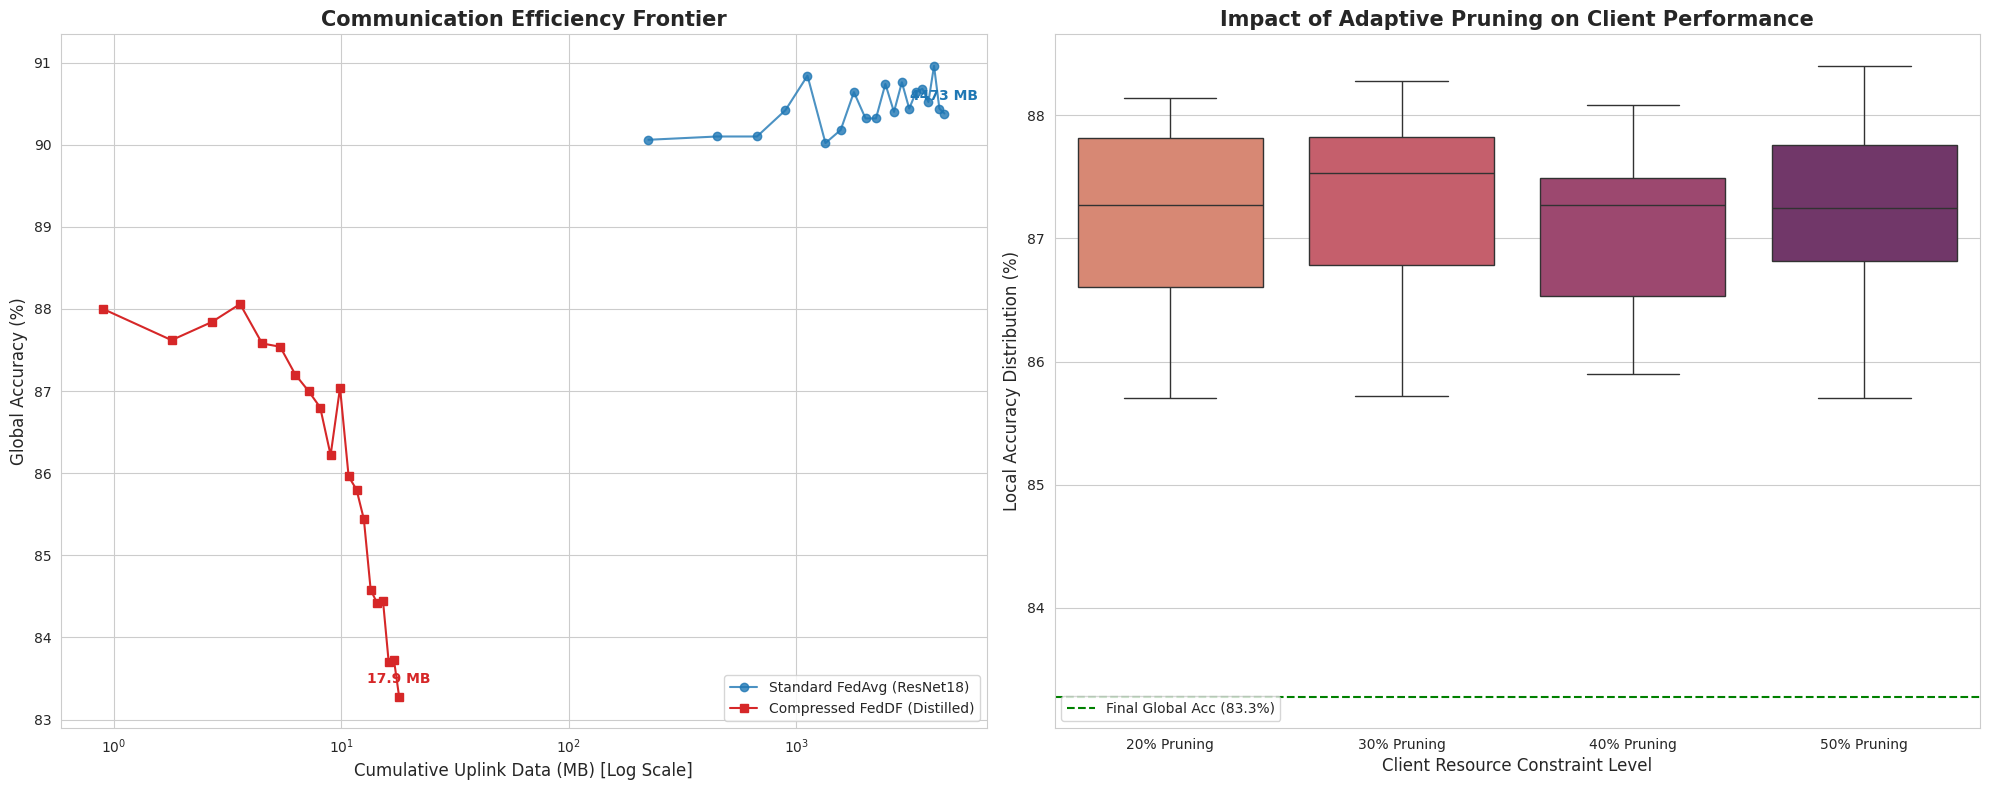

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


avg_std_round_cost = std_cost / FED_ROUNDS
std_comm_hist = [avg_std_round_cost * i for i in range(1, FED_ROUNDS + 1)]
client_plot_data = []
pruning_labels = {i: f"{CLIENT_PRUNING_RATES[i]*100:.0f}% Pruning" for i in range(TOTAL_CLIENTS)}

for client_id, accuracies in client_acc_hist.items():
    for acc in accuracies:
        client_plot_data.append({
            'Client Config': pruning_labels[client_id],
            'Accuracy (%)': acc
        })
df_clients = pd.DataFrame(client_plot_data)

# --- Plotting ---
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

#accuracy vs data transferred 
ax1 = axes[0]
ax1.plot(std_comm_hist, std_acc, label='Standard FedAvg (ResNet18)', color='tab:blue', marker='o', alpha=0.8)
ax1.plot(feddf_comm_hist, feddf_acc, label='Compressed FedDF (Distilled)', color='tab:red', marker='s')

ax1.set_xscale('log') 
ax1.set_title('Communication Efficiency Frontier', fontsize=15, weight='bold')
ax1.set_xlabel('Cumulative Uplink Data (MB) [Log Scale]', fontsize=12)
ax1.set_ylabel('Global Accuracy (%)', fontsize=12)
ax1.legend(loc='lower right')

ax1.annotate(f"{std_cost:.0f} MB", (std_cost, std_acc[-1]), textcoords="offset points", xytext=(0,10), ha='center', weight='bold', color='tab:blue')
ax1.annotate(f"{feddf_cost:.1f} MB", (feddf_cost, feddf_acc[-1]), textcoords="offset points", xytext=(0,10), ha='center', weight='bold', color='tab:red')

#client heterogeneity boxplots
ax2 = axes[1]
sns.boxplot(data=df_clients, x='Client Config', y='Accuracy (%)', hue='Client Config', palette='flare', ax=ax2, legend=False)
ax2.axhline(feddf_acc[-1], color='green', linestyle='--', label=f'Final Global Acc ({feddf_acc[-1]:.1f}%)')

ax2.set_title('Impact of Adaptive Pruning on Client Performance', fontsize=15, weight='bold')
ax2.set_xlabel('Client Resource Constraint Level', fontsize=12)
ax2.set_ylabel('Local Accuracy Distribution (%)', fontsize=12)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.savefig('federated_learning_analysis.png', dpi=300)
plt.show()

P.S. plotting was done with LLM assistance